# 03 · Radial velocities with a cross-correlation (UNICOR)

**What you'll learn**

- the cross-correlation function (CCF): built by hand, then with `unicor.ccf_order`
- the RV as the CCF peak, and its uncertainty from the peak's shape (Zucker 2003):
  `unicor.measure_rv`
- how to combine the CCFs of several orders (`unicor.combine_ccfs`), and how to check the error
  bars against a simulated truth
- an RV of a real star, TOI-677 (NRES), from the loader, the `sparta.preprocess` steps and a
  PHOENIX template broadened on a ln-λ grid

In [1]:
# Imports: UNICOR atoms, instrument loaders, preprocessing steps, plot style
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import unicor
from sparta import instruments
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_spectra
from sparta.preprocess import (bandpass, coarsest_native_step, remove_cosmics,
                               resample_to_linear_grid, resample_to_log_grid, trim_margins)
from sparta.template import phoenix_spectrum
from sparta.plotting import (EXTRA_COLOR, MODEL_COLOR, apply_style, plot_curve, plot_data,
                             plot_points)

# Apply the SPARTA figure style
apply_style()
c = unicor.C_KMS                     # speed of light, km/s

## 1. The CCF by hand

The idea: slide a template across the observed spectrum and, at every trial shift, measure how
well the two match. On a log-λ grid (notebook 02) a shift of *k* pixels is one velocity, so the
match as a function of *k* is a function of velocity, and it peaks at the star's RV.

A toy "star": 25 Gaussian lines on a 0.5 km/s log-λ grid, observed at 12.3 km/s with a little noise.

In [2]:
# Draw the toy star's line positions (Å) and depths
rng = np.random.default_rng(0)
centres, depths = rng.uniform(5002, 5048, 25), rng.uniform(0.2, 0.7, 25)

# Noiseless spectrum of the toy star: a sum of Gaussian absorption lines
def toy_star(wave):
    '''Normalised spectrum: 25 Gaussian absorption lines of σ = 3 km/s.'''
    sigma = 3.0 / c * centres
    return 1 - np.sum(depths * np.exp(-0.5 * ((wave[:, None] - centres) / sigma) ** 2), axis=1)

# Build a 0.5 km/s log-λ grid; observe the star shifted by v_true, plus noise
dv, v_true = 0.5, 12.3                                     # km/s
wave, _ = unicor.log_lambda_grid(5000.0, 5050.0, dv)
observed = toy_star(wave / unicor.doppler_factor(v_true)) + 0.02 * rng.standard_normal(wave.size)

To scan ±K pixels the template must also exist K pixels beyond each end of the observed grid,
so every lag compares the *same* observed pixels (`unicor.extend_log_grid`; why:
[correlation engines § the CCF](../../docs/correlation_engines.md#the-ccf)). At lag *k* the match is the Pearson correlation
of the observed pixels with the template moved by *k*:

In [3]:
# Extend the grid K pixels at each end, so every lag has template to compare
K = 40                                                     # lags each side: ±20 km/s
t_wave = unicor.extend_log_grid(wave, K)                   # N + 2K wavelengths (Å)
# Evaluate the star at rest on the extended grid: this is the template
template = toy_star(t_wave)                                # the template, at rest
N = wave.size

# CCF by hand: Pearson correlation with the template moved by k pixels
lags = np.arange(-K, K + 1)
ccf_hand = np.array([np.corrcoef(observed, template[K - k: K - k + N])[0, 1] for k in lags])

`unicor.ccf_order` does the same for one order. It takes the template on *any* increasing grid
(here the extended one) and interpolates it linearly onto the lags itself, correlates only the
observed pixels the template covers at every lag (`lo:hi`, here all of them), and returns a
frozen `CCFOrder` ([open API § the per-order CCF](../../docs/open_api.md#unicor--the-per-order-ccf-unicorccf)).

In [4]:
# Same CCF with the library (unicor.ccf_order), with its RV and error
order = unicor.ccf_order(wave, observed, t_wave, template, K, dv_kms=dv, native_step_kms=dv,
                         errors=True)
# Report which pixels were correlated and compare with the hand-made CCF
print(f"correlated pixels {order.lo}:{order.hi} of {N}; {order.velocity.size} lags, "
      f"{order.velocity[0]:.2f} to {order.velocity[-1]:.2f} km/s")
print(f"max |by hand - unicor.ccf_order| = {np.max(np.abs(order.ccf - ccf_hand)):.1e}")
# The library CCF must equal the hand-made one
assert np.allclose(order.ccf, ccf_hand, rtol=0, atol=1e-12)

correlated pixels 0:5967 of 5967; 81 lags, -20.00 to 20.00 km/s
max |by hand - unicor.ccf_order| = 1.1e-14


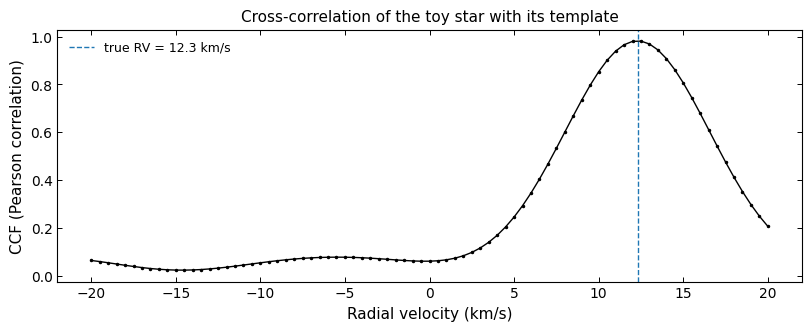

In [5]:
# The CCF against velocity: a peak at the true RV (dashed)
fig, ax = plt.subplots()
plot_curve(ax, order.velocity, order.ccf, marker=".", ms=3)
ax.axvline(v_true, color=EXTRA_COLOR, ls="--", lw=1, label=f"true RV = {v_true} km/s")
ax.set_xlabel("Radial velocity (km/s)")
ax.set_ylabel("CCF (Pearson correlation)")
ax.set_title("Cross-correlation of the toy star with its template")
ax.legend()
plt.show()

## 2. The peak and its uncertainty

The RV is the peak of the CCF, located between lags with a parabola (`unicor.subpixel_peak`).
Its uncertainty follows from the CCF's shape at the peak (Zucker 2003):

$$\sigma_v^2 = -\left[N\,\frac{C''(v)\,C(v)}{1 - C^2(v)}\right]^{-1}$$

A sharper (larger $|C''|$) and higher ($C$ closer to 1) peak, and more independent pixels $N$,
give a smaller error (`unicor.rv_uncertainty`; details in
[correlation engines § RV and its uncertainty](../../docs/correlation_engines.md#rv-and-its-uncertainty)). Here every pixel is
independent (the native step is the grid step), so $N$ is the number of pixels.
`unicor.measure_rv` is these two calls in one, and `ccf_order(..., errors=True)` already made them:

In [6]:
# The RV is the CCF peak (parabola fit); the error comes from its shape
rv, peak = unicor.subpixel_peak(order.velocity, order.ccf)
erv = unicor.rv_uncertainty(order.velocity, order.ccf, rv, n_eff=N)
# Compare the measured RV with the truth, in units of its error
print(f"RV = {rv:.4f} ± {erv:.4f} km/s   (truth {v_true}; off by {(rv - v_true) / erv:+.1f} σ)")
print(f"CCF peak = {peak:.3f}, N = {N} pixels, n_eff = {order.n_eff:.0f}")

# measure_rv does both steps at once; the three results must agree exactly
m = unicor.measure_rv(order.velocity, order.ccf, order.n_eff)
assert (m.rv, m.erv, m.peak) == (rv, erv, peak) == (order.rv, order.erv, order.peak)

RV = 12.2934 ± 0.0106 km/s   (truth 12.3; off by -0.6 σ)
CCF peak = 0.982, N = 5967 pixels, n_eff = 5967


## 3. A simulated star with several orders

`sparta.instruments.Simulation` makes spectra as a real product would record them, at RVs we
choose: here a PHOENIX model (5800 K) observed "like HARPS" (its resolving power, pixel size and
air wavelengths) in three 50 Å orders, 60 epochs, signal-to-noise 50 per pixel. The `SIMULATED`
product's `load` returns the records (plain arrays) and the truth; `component_spectra(sim)` the
noiseless rest-frame model, order by order: a perfectly matched template.

In [7]:
# 60 random epochs (days) and a true RV curve: circular orbit + systemic (km/s)
rng = np.random.default_rng(2)
times = np.sort(rng.uniform(0, 60, 60))                            # days
rv_true = 5.0 + 12.0 * np.sin(2 * np.pi * times / 9.0)             # km/s

# Simulate HARPS-like spectra of a 5800 K model: 3 orders, S/N 50
sim = Simulation(like="HARPS", components=[dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0)],
                 windows_A=[(5000, 5050), (5200, 5250), (5500, 5550)],
                 times=times, rv_kms=rv_true, snr=50, noise="constant", seed=3)
# Load the simulated records and the truth; get the noiseless rest-frame templates per order
sim_records, truth = instruments.get("SIMULATED").load(sim)
sim_templates = component_spectra(sim)[0]                         # [(wave, flux)] per order
# Check what one record holds
print(f"{len(sim_records)} epochs, {len(sim_records[0].wave)} orders, "
      f"bcv = {sim_records[0].bcv} km/s (HARPS-like: already barycentric)")

60 epochs, 3 orders, bcv = 0.0 km/s (HARPS-like: already barycentric)


One epoch, step by step. Every order goes onto a log-λ grid of the same step `dv`
(`resample_to_log_grid`). The simulated pixels are the native ones, so each order's native step
is its own grid's (`unicor.dv_from_wave`); the error counts native pixels
([conventions § native sampling](../../docs/conventions.md#native-sampling-and-the-number-of-independent-pixels)).
`unicor.lag_axis` checks that all orders share the step and gives their common velocity axis;
then `ccf_order` runs once per order.

In [8]:
# Settings: log-λ step dv and the ±40 km/s scan, in pixels K
dv, vel_bound = 0.1, 40.0                                          # km/s
K = int(round(vel_bound / dv))
# Take epoch 0
r = sim_records[0]

# Native pixel step of each order (km/s), needed for the number of independent pixels
natives = [unicor.dv_from_wave(w) for w in r.wave]                 # km/s
# Resample every order onto a log-λ grid of step dv (resample_to_log_grid)
waves, fluxes = zip(*(resample_to_log_grid(w, s, dv) for w, s in zip(r.wave, r.flux)))
# Check that the orders share the step and get the common lag velocities (km/s)
_, v = unicor.lag_axis(waves, dv, K)
# One CCF per order, each against its own template (unicor.ccf_order)
orders = [unicor.ccf_order(w, s, tw, tf, K, dv_kms=dv, native_step_kms=n, errors=True)
          for w, s, n, (tw, tf) in zip(waves, fluxes, natives, sim_templates)]
# Print each order's RV and error
for i, o in enumerate(orders):
    print(f"order {i}: RV = {o.rv:.4f} ± {o.erv * 1e3:.1f} m/s, n_eff = {o.n_eff:.0f}")

order 0: RV = 16.9913 ± 5.2 m/s, n_eff = 4887
order 1: RV = 16.9910 ± 5.9 m/s, n_eff = 4700
order 2: RV = 16.9920 ± 8.0 m/s, n_eff = 4444


**Combining the orders** (Zucker 2003). If order *i* has $N_i$ independent pixels and CCF
$C_i(v)$, the maximum-likelihood combination is
$1 - C^2(v) = \prod_i \left[1 - C_i^2(v)\right]^{N_i/N}$, $N = \sum_i N_i$ (`unicor.combine_ccfs`;
[correlation engines § combining orders](../../docs/correlation_engines.md#combining-orders-zucker-2003)). The combined RV
behaves like a weighted average of the orders', and its error like their inverse-variance
combination:

In [9]:
# Stack the per-order CCFs with their numbers of independent pixels
ccfs = np.array([o.ccf for o in orders])
n_eff = np.array([o.n_eff for o in orders])
# Combine the orders by maximum likelihood (Zucker 2003) and read the RV from the result
combined = unicor.combine_ccfs(ccfs, n_eff=n_eff)
comb = unicor.measure_rv(v, combined, n_eff.sum())

# Compare with the inverse-variance combination of the per-order errors
per_err = np.array([o.erv for o in orders])
print(f"combined: RV = {comb.rv:.4f} ± {comb.erv * 1e3:.1f} m/s   (truth {truth.rv_kms[0, 0]:.4f})")
print(f"inverse-variance combination of the order errors: {1e3 / np.sqrt(np.sum(per_err ** -2)):.1f} m/s")

combined: RV = 16.9913 ± 3.5 m/s   (truth 16.9872)
inverse-variance combination of the order errors: 3.5 m/s


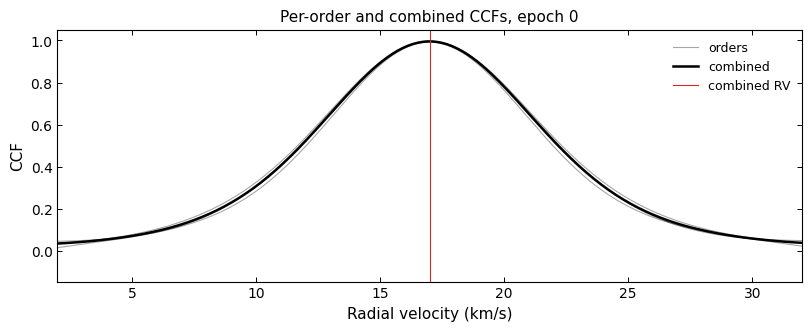

In [10]:
# Each order's CCF (faint) and the combined CCF (bold), zoomed on the peak
fig, ax = plt.subplots()
for i, cc in enumerate(ccfs):
    plot_curve(ax, v, cc, lw=0.8, alpha=0.35, label="orders" if i == 0 else None)
plot_curve(ax, v, combined, lw=1.8, label="combined")
ax.axvline(comb.rv, color=MODEL_COLOR, lw=0.8, label="combined RV")
ax.set_xlim(comb.rv - 15, comb.rv + 15)
ax.set_xlabel("Radial velocity (km/s)")
ax.set_ylabel("CCF")
ax.set_title("Per-order and combined CCFs, epoch 0")
ax.legend()
plt.show()

**The log-likelihood.** Zucker's $\ln L(v) = -\sum_i \tfrac{N_i}{2}\ln\left(1 - C_i^2(v)\right)$ is
the sum of the orders' `CCFOrder.loglike` and equals $-\tfrac{N}{2}\ln(1 - C^2)$ of the combined
CCF (`combine_ccfs(..., output='loglike')`; [correlation engines § two output modes](../../docs/correlation_engines.md#two-output-modes)).
It peaks at the same lag, and its curvature there gives the error above: $\sigma_v^2 = -1/(\ln L)''$.

In [11]:
# The log-likelihood of the combined orders, three ways: they must agree
lnl = unicor.combine_ccfs(ccfs, n_eff=n_eff, output="loglike")
assert np.allclose(lnl, sum(o.loglike for o in orders), rtol=1e-12, atol=0)
assert np.allclose(lnl, -(n_eff.sum() / 2) * np.log(1 - combined ** 2), rtol=1e-12, atol=0)
assert np.argmax(lnl) == np.argmax(combined)

# Error from the curvature of ln L at its peak (finite difference), against measure_rv
j = np.argmax(lnl)
curvature = (lnl[j + 1] - 2 * lnl[j] + lnl[j - 1]) / dv ** 2         # finite difference, 1/(km/s)^2
print(f"sigma from the curvature of ln L: {1e3 / np.sqrt(-curvature):.1f} m/s;  "
      f"measure_rv: {comb.erv * 1e3:.1f} m/s")

sigma from the curvature of ln L: 3.6 m/s;  measure_rv: 3.5 m/s


## 4. Are the error bars honest?

With the truth known, the scatter of (measured − true) over many epochs should match the reported
uncertainties. The cells above, wrapped into one function, give the RV of any epoch:

In [12]:
# The steps of this section for one epoch, as one function
def unicor_rv(waves, fluxes, natives, templates, dv, vel_bound, velocity_convention="cz"):
    '''RV of one epoch: per-order CCFs on a log-λ grid of step dv (km/s), combined (Zucker 2003).

    Returns the lag velocities (km/s), the CCFOrder of each order, the combined CCF and the
    RVMeasurement read from it (km/s).
    '''
    K = int(round(vel_bound / dv))
    waves, fluxes = zip(*(resample_to_log_grid(w, s, dv) for w, s in zip(waves, fluxes)))
    _, v = unicor.lag_axis(waves, dv, K, velocity_convention)
    orders = [unicor.ccf_order(w, s, tw, tf, K, dv_kms=dv, native_step_kms=n,
                               velocity_convention=velocity_convention)
              for w, s, n, (tw, tf) in zip(waves, fluxes, natives, templates)]
    n_eff = np.array([o.n_eff for o in orders])
    combined = unicor.combine_ccfs(np.array([o.ccf for o in orders]), n_eff=n_eff)
    return v, orders, combined, unicor.measure_rv(v, combined, n_eff.sum())

# The function must reproduce the epoch-0 result above
assert unicor_rv(r.wave, r.flux, natives, sim_templates, dv, vel_bound)[-1] == comb

In [13]:
# Run the function on all 60 epochs and collect RVs and errors
sim_fits = [unicor_rv(r.wave, r.flux, [unicor.dv_from_wave(w) for w in r.wave], sim_templates,
                      dv, vel_bound)[-1] for r in sim_records]
rv_sim = np.array([f.rv for f in sim_fits])
erv_sim = np.array([f.erv for f in sim_fits])
# Residuals: measured minus true RV (km/s)
resid = rv_sim - truth.rv_kms[:, 0]
n = resid.size

# Honest errors: the scatter of the residuals should match the reported error
print(f"scatter of (measured - true): {np.std(resid, ddof=1) * 1e3:.2f} m/s")
print(f"mean reported uncertainty:    {np.mean(erv_sim) * 1e3:.2f} m/s")
print(f"ratio: {np.std(resid, ddof=1) / np.mean(erv_sim):.2f}  "
      f"(1 expected; ±{1 / np.sqrt(2 * (n - 1)):.2f} from {n} epochs alone)")
print(f"within 1σ of the truth: {np.mean(np.abs(resid) < erv_sim):.0%}  (68% expected)")

scatter of (measured - true): 3.31 m/s
mean reported uncertainty:    3.50 m/s
ratio: 0.95  (1 expected; ±0.09 from 60 epochs alone)
within 1σ of the truth: 73%  (68% expected)


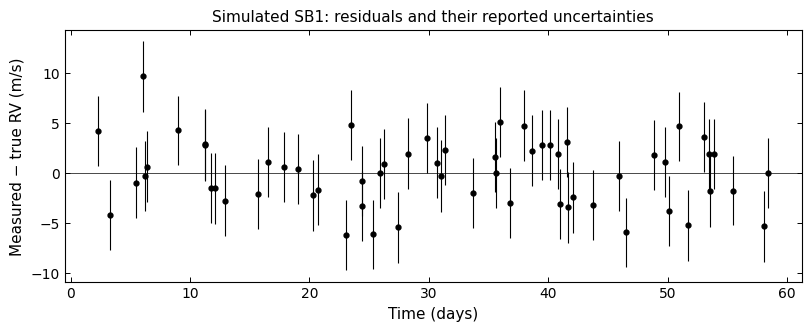

In [14]:
# Residuals against time, with reported errors as bars, scattered about zero
fig, ax = plt.subplots()
ax.axhline(0, color="k", lw=0.5)
plot_points(ax, times, resid * 1e3, erv_sim * 1e3)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Measured − true RV (m/s)")
ax.set_title("Simulated SB1: residuals and their reported uncertainties")
plt.show()

The noise here is white on the native pixels, which is what the uncertainty formula assumes.

## 5. Real data: TOI-677 with NRES

Now the full recipe on the 12 bundled NRES spectra, from the files to the RVs, one step at a
time. First the data (notebook 01) and the settings `sparta.instruments` recommends for this
product ([instruments § NRES](../../docs/instruments.md#nres)): drop the 10 reddest and 17 bluest
orders, then preprocess every order.

In [15]:
# The NRES product and its recommended settings
nres = instruments.get("NRES")
rec = nres.recommended
pp = rec.preprocess
# Load the 12 NRES spectra
records = [nres.load(p, min_wv=None, max_wv=None) for p in sorted(Path("../data/TOI677").glob("*.fits"))]
# Keep the orders that are not recommended for dropping
keep = [i for i in range(len(records[0].wave)) if i not in rec.drop_orders]
# Summarise
print(f"{len(records)} epochs, {len(keep)} of {len(records[0].wave)} orders kept")
print("recommended preprocess:", pp)

12 epochs, 40 of 67 orders kept
recommended preprocess: {'n_trim': 100, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'continuum_scale_kms': 1400.0, 'noise_scale_kms': 9.6, 'alpha': 0.3}


**Preprocessing**, in this order (`sparta.preprocess`): `trim_margins` (NaNs, unexposed margins
and `n_trim` more pixels), `resample_to_linear_grid` (an even grid, which the filter needs;
`coarsest_native_step` keeps the native step), `remove_cosmics`, `bandpass` (removes the
continuum and the pixel-to-pixel noise, leaving a zero-mean, unit-variance spectrum) and a Tukey
taper (`unicor.tukey_window`). What each step does and why in this order:
[conventions § preprocessing order](../../docs/conventions.md#preprocessing-order). Each order is first moved to
the barycentric frame (`doppler_shift_wave(wave, bcv)`, notebook 01).

In [16]:
# One order through the recommended preprocessing chain
def preprocess_order(wave, flux):
    '''One order through the recommended chain: wave (Å), flux, native step (km/s).'''
    # Cut NaNs and unexposed margins
    wave, flux = trim_margins(wave, flux, n_left=pp["n_trim"], n_right=pp["n_trim"],
                              clean_margins=pp["clean_margins"], remove_nans=pp["remove_nans"])
    # Remember the native step, before resampling changes it
    native = unicor.dv_from_wave(wave)                 # NRES pixels are the detector's
    # Resample onto an even linear grid, which the filter needs
    wave, flux = resample_to_linear_grid(wave, flux, pp["delta"])
    native = coarsest_native_step(native, wave)
    # Remove cosmic-ray spikes
    flux = remove_cosmics(wave, flux, sigma_upper=pp["cosmic_sigma"])
    # Band-pass filter: removes the continuum and pixel-to-pixel noise
    flux = bandpass(wave, flux, pp["continuum_scale_kms"], pp["noise_scale_kms"], order=1)
    # Taper the ends smoothly to zero
    flux = flux * unicor.tukey_window(flux.size, pp["alpha"])
    return wave, flux, native

# Move the kept orders of one record to the barycentric frame, then preprocess them
def prepare_epoch(record):
    '''The kept orders of one record, barycentric and preprocessed: lists of wave, flux, native.'''
    out = [preprocess_order(unicor.doppler_shift_wave(record.wave[i], record.bcv), record.flux[i])
           for i in keep]
    return [list(x) for x in zip(*out)]

# Preprocess all epochs; epoch 0's wavelengths are the reference
epochs = [prepare_epoch(r) for r in records]
waves0 = epochs[0][0]
# Summarise
print(f"epoch 0: {len(waves0)} orders; native steps {min(epochs[0][2]):.3f}-"
      f"{max(epochs[0][2]):.3f} km/s")

epoch 0: 40 orders; native steps 1.433-1.483 km/s


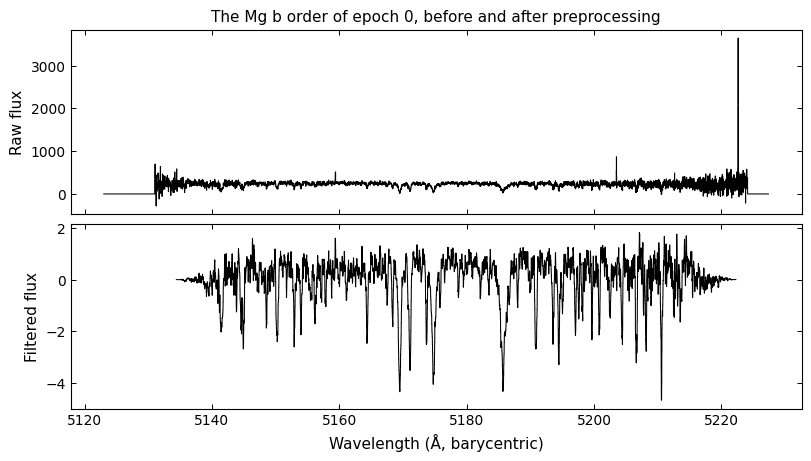

In [17]:
# Pick the Mg b order of epoch 0 and its barycentric wavelengths
o = next(j for j, w in enumerate(waves0) if w[0] < 5175 < w[-1])     # the Mg b order
raw_w = unicor.doppler_shift_wave(records[0].wave[keep[o]], records[0].bcv)
# Top: the raw order. Bottom: after preprocessing (flat, zero-mean, tapered)
fig, axs = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
plot_data(axs[0], raw_w, records[0].flux[keep[o]])
axs[0].set_ylabel("Raw flux")
axs[0].set_title("The Mg b order of epoch 0, before and after preprocessing")
plot_data(axs[1], waves0[o], epochs[0][1][o])
axs[1].set_ylabel("Filtered flux")
axs[1].set_xlabel("Wavelength (Å, barycentric)")
plt.show()

**The template.** A PHOENIX model from the bundled cache (5800 K, log g 3.5, [Fe/H] +0.5, the
closest bundled model; a mismatch lowers the CCF peak and so inflates the errors). NRES does not
document its wavelength frame, so we keep PHOENIX's vacuum wavelengths
([conventions § air and vacuum](../../docs/conventions.md#air-and-vacuum-wavelengths)).

In [18]:
# Wavelength range covered by the observed orders (Å)
lo, hi = min(w[0] for w in waves0), max(w[-1] for w in waves0)
# Load the PHOENIX model from the bundled cache, with 10 Å to spare (vacuum, Å)
t_wave, t_flux = phoenix_spectrum(5800, 3.5, 0.5, wave_range=(lo - 10, hi + 10),
                                  allow_download=False)
# Its pixel step in velocity (km/s)
step = c * np.diff(t_wave) / t_wave[:-1]                           # km/s per PHOENIX pixel
# Show that the step is not constant in velocity
print(f"PHOENIX: {t_wave.size} pixels over {lo - 10:.0f}-{hi + 10:.0f} Å (vacuum)")
for lam in (4600, 4999, 5001, 7500):
    j = np.searchsorted(t_wave, lam)
    print(f"  step at {lam} Å: {np.diff(t_wave)[j]:.3f} Å = {step[j]:.3f} km/s")

PHOENIX: 332451 pixels over 4566-7601 Å (vacuum)
  step at 4600 Å: 0.006 Å = 0.391 km/s
  step at 4999 Å: 0.006 Å = 0.360 km/s
  step at 5001 Å: 0.010 Å = 0.599 km/s
  step at 7500 Å: 0.010 Å = 0.400 km/s


**Broadening needs a velocity-even grid.** The star's rotation (v sin i) and the spectrograph's
line-spread function (FWHM $c/R$) have one width *in velocity* at every wavelength. A
convolution kernel is a fixed number of pixels, so it has one velocity width only if every pixel
spans the same velocity: a ln-λ grid. PHOENIX is linear in λ, with a step that jumps from
0.006 to 0.01 Å at 5000 Å: in velocity, from 0.36 to 0.60 km/s. A kernel sized for one step would
be 1.7 times too wide or too narrow on the other side; one sized for the order's median step
(what `Template` did before SPARTA 0.3.0) is off by 0.8–1.35 times over this template's range.

So: resample onto a ln-λ grid at the finest velocity step, convolve there with
`unicor.broaden_rotational` and `unicor.broaden_gaussian`, and resample back onto the PHOENIX
wavelengths, as `Template.broaden_rotational` and `broaden_instrumental` do. (The kernels act on
flux − 1, as for a normalised spectrum; on PHOENIX's un-normalised flux only the pixels within a
kernel width of the ends are affected, and those lie in the margin cut away below.)

In [19]:
# Apply a broadening kernel on a ln-λ grid, then return to the original wavelengths
def broaden_on_log_grid(wave, flux, kernel):
    '''Apply kernel(flux, dv) on a uniform ln-λ grid and resample back onto wave (Å).'''
    dv_fine = c * np.min(np.diff(wave) / wave[:-1])                # km/s, the finest step
    grid, _ = unicor.log_lambda_grid(wave[0], wave[-1], dv_fine)
    on_grid = unicor.resample(wave, flux, grid, kind="cubic")
    return unicor.resample(grid, kernel(on_grid, dv_fine), wave, kind="cubic")

# Stellar rotation and limb darkening; instrumental line-spread width c/R (km/s)
vsini, epsilon = 6.0, 0.5                                          # km/s, limb darkening
fwhm = c / nres.instrument.resolving_power                         # km/s
# Broaden the template by rotation, then by the instrument profile
t_broad = broaden_on_log_grid(t_wave, t_flux,
                              lambda f, d: unicor.broaden_rotational(f, d, vsini, epsilon))
t_broad = broaden_on_log_grid(t_wave, t_broad,
                              lambda f, d: unicor.broaden_gaussian(f, d, fwhm))

# Check that the kernel is the same number of pixels everywhere
d_fine = c * np.min(np.diff(t_wave) / t_wave[:-1])
print(f"ln-λ grid step {d_fine:.3f} km/s: the rotational kernel spans "
      f"{unicor.rotational_kernel(d_fine, vsini, epsilon).size} pixels, everywhere")

ln-λ grid step 0.360 km/s: the rotational kernel spans 33 pixels, everywhere


Then the template is cut into the observed orders, each with a 150 km/s margin so that every lag
of the ±100 km/s scan finds template, and passed through the same preprocessing *settings* as the
data (a filtered spectrum must be correlated with a filtered template). The settings are in
pixel units, so on the template's finer pixels they are not quite the same filter
([limitations § spectra and templates](../../docs/limitations.md#spectra-and-templates)).
We follow the object path here.

In [20]:
# Template margin around each order: 150 km/s, as a ln-λ fraction
margin = 150.0 / c                                                 # 150 km/s, as ln-λ
# Cut the template to each observed order and preprocess it like the data
templates = []
for w in waves0:
    inside = (t_wave >= w.min() * (1 - margin)) & (t_wave <= w.max() * (1 + margin))
    tw, tf, _ = preprocess_order(t_wave[inside], t_broad[inside])
    templates.append((tw, tf))
# Summarise
print(f"template: {len(templates)} orders")

template: 40 orders


**The RVs**: `unicor_rv` from section 4, epoch by epoch, at the recommended step (0.05 km/s)
over ±100 km/s.

In [21]:
# The recommended step and the ±100 km/s scan
dv_nres, bound_nres = rec.dv_kms, 100.0                            # km/s
# RV of every epoch (unicor_rv)
fits = [unicor_rv(w, s, n, templates, dv_nres, bound_nres) for w, s, n in epochs]
# Collect the RVs and errors (km/s)
rv_nres = np.array([f[-1].rv for f in fits])
erv_nres = np.array([f[-1].erv for f in fits])

# Times, counted from the first integer day
bjd = np.array([r.time for r in records])
t = bjd - int(bjd.min())                                           # days
# Summarise the RVs
print(f"mean RV = {rv_nres.mean():.3f} km/s, rms = {rv_nres.std() * 1e3:.0f} m/s, "
      f"median uncertainty = {np.median(erv_nres) * 1e3:.0f} m/s")

mean RV = 38.182 km/s, rms = 75 m/s, median uncertainty = 24 m/s


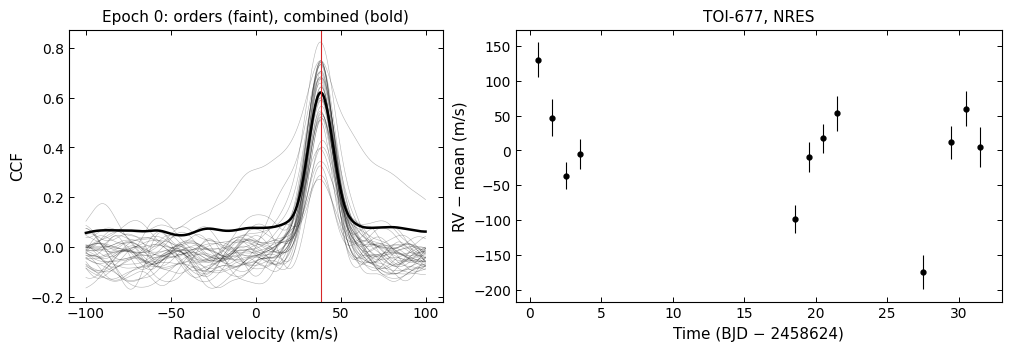

In [22]:
# Epoch 0's CCFs, and the RV curve of all 12 epochs
v0, orders0, combined0, m0 = fits[0]
# Left: per-order and combined CCFs of epoch 0. Right: RVs minus their mean, with errors
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": (1, 1.3)})
for od in orders0:
    plot_curve(axs[0], v0, od.ccf, lw=0.4, alpha=0.3)
plot_curve(axs[0], v0, combined0, lw=1.8)
axs[0].axvline(m0.rv, color=MODEL_COLOR, lw=0.8)
axs[0].set_xlabel("Radial velocity (km/s)")
axs[0].set_ylabel("CCF")
axs[0].set_title("Epoch 0: orders (faint), combined (bold)")
plot_points(axs[1], t, (rv_nres - rv_nres.mean()) * 1e3, erv_nres * 1e3)
axs[1].set_xlabel(f"Time (BJD − {int(bjd.min())})")
axs[1].set_ylabel("RV − mean (m/s)")
axs[1].set_title("TOI-677, NRES")
plt.show()

TOI-677 varies by far more than its error bars: it hosts a giant planet on an 11-day
eccentric orbit (Jordán et al. 2020), and notebooks 06 and 09 show how to look for such a period.
After band-pass filtering the uncertainties are conservative, not exactly calibrated
([conventions § error bars](../../docs/conventions.md#when-are-the-error-bars-calibrated)).

## A note on `velocity_convention`

A wavelength ratio becomes a velocity through a convention: 'cz' by default
($\lambda_{\rm obs}/\lambda_{\rm rest} = 1 + v/c$), or `velocity_convention='relativistic'`. The two
differ by about $v^2/2c$ ([conventions § velocity convention](../../docs/conventions.md#velocity-convention)):

In [23]:
# The same epoch under the 'cz' and the relativistic convention
rv_cz = fits[0][-1].rv
rv_rel = unicor_rv(*epochs[0], templates, dv_nres, bound_nres,
                   velocity_convention="relativistic")[-1].rv
# Their difference should be about v²/2c
print(f"cz - relativistic = {(rv_cz - rv_rel) * 1e3:.3f} m/s;  v²/2c = {rv_cz ** 2 / (2 * c) * 1e3:.3f} m/s")

cz - relativistic = 2.448 m/s;  v²/2c = 2.448 m/s


Small, but not negligible for precise work: compare RVs only within one convention.

## The same RVs with the objects

`Observations`, `Spectrum.preprocess`, `Template` and `CCF1d` chain the same atoms
([`howto/01_measure_rvs`](../howto/01_measure_rvs.ipynb) is the short recipe): the RVs and
uncertainties are identical, bit for bit.

In [24]:
# The object path: load, drop orders and preprocess the data
from sparta import Observations, Template

obs = Observations(survey="NRES", target_visits_lib="../data/TOI677/")
obs.select_orders(list(rec.drop_orders), remove=True)
obs.preprocess(**pp)

# Build the same template: load, broaden, cut to the orders, preprocess
tmpl = Template.from_phoenix(5800, 3.5, 0.5, wave_range=(lo - 10, hi + 10), allow_download=False)
tmpl.broaden_rotational(vsini=vsini, epsilon=epsilon)
tmpl.broaden_instrumental(resolution=nres.instrument.resolving_power)
tmpl.cut_multiorder_like(obs.spec_list[0], margins=150)
tmpl.model.preprocess(**pp)

# Measure the RVs
obs.calc_rv_against_template(tmpl, dv=dv_nres, vel_bound=bound_nres)
# The objects must give the same numbers, bit for bit
assert np.array_equal(obs.vels, rv_nres) and np.array_equal(obs.evels, erv_nres)
print("Observations.calc_rv_against_template: the same", obs.sample_size, "RVs and errors")

Observations.calc_rv_against_template: the same 12 RVs and errors


## Summary / next

- The CCF is a Pearson correlation of the spectrum with the shifted template; its peak is the RV
  (`unicor.ccf_order`, `unicor.measure_rv`).
- The uncertainty comes from the peak's height and curvature and the number of *independent*
  pixels; on a simulated star the reported errors match the actual scatter.
- Orders are combined by maximum likelihood (`unicor.combine_ccfs`, Zucker 2003).
- Real data need preprocessing (`sparta.preprocess`) and a template broadened on a ln-λ grid and
  processed the same way.

**Next:** [`04_todcor`](04_todcor.ipynb): two stars at once.